In [1]:
import pandas as pd
import numpy as np
import mlflow
from pathlib import Path
from IPython.display import display, Markdown

# ==========================================
# 1. SETUP PATH & MLFLOW
# ==========================================
root_path = Path.cwd().parent
import os
from dotenv import load_dotenv
load_dotenv(dotenv_path=root_path / ".env") # Load variabel dari .env
# Gunakan DagsHub URI jika ada di .env, jika tidak pakai folder lokal mlruns
tracking_uri = os.getenv("MLFLOW_TRACKING_URI", (root_path / "mlruns").as_uri())
mlflow.set_tracking_uri(tracking_uri)
mlflow.set_experiment("03_Data_Preprocessing")

with mlflow.start_run(run_name="Data_Cleaning_and_Engineering"):
    print("⏳ 1. Memuat Data Mentah...")
    df = pd.read_csv(root_path / "Data/raw/Dataset.csv")
    
    # Simpan jumlah awal untuk tracking
    initial_count = len(df)

    # ==========================================
    # 2. DATA CLEANING & PENANGANAN OUTLIER
    # ==========================================
    print("⏳ 2. Cleaning & Penanganan Outlier Usia...")
    # Sesuai fokus penelitian: Remaja (10-18 tahun)
    # Ini secara otomatis membuang outlier umur 1998 tahun
    df = df[(df['age'] >= 10) & (df['age'] <= 18)].copy()
    
    # Menghapus kolom teknis yang tidak memiliki nilai psikososial
    # Kolom berakhiran E (waktu) dan I (posisi soal)
    tech_cols = [c for c in df.columns if c.endswith('E') or c.endswith('I')] + \
                ['introelapse', 'testelapse', 'surveyelapse', 'screensize', 
                 'uniquenetworklocation', 'source', 'hand']
    df = df.drop(columns=tech_cols, errors='ignore')
    
    # Menghapus kolom VCL1-16 (Vocabulary Checklist)
    # Kolom ini hanya digunakan untuk validasi atensi responden, bukan fitur psikososial
    vcl_cols = [f"VCL{i}" for i in range(1, 17)]
    df = df.drop(columns=vcl_cols, errors="ignore")
    
    # Menghapus fitur demografis yang tidak relevan untuk konteks penelitian di Indonesia
    # - engnat: English as native language, tidak relevan untuk responden Indonesia
    # - orientation: orientasi seksual, di luar cakupan penelitian psikososial remaja
    # - married : Penelitian ini di khususkan bagi usia Remaja
    # - race : Kategori ras global tidak merepresentasikan Indonesia
    # - voted : Tidak ada landasan klinis untuk kesehatan mental remaja
    demo_drop_cols = ["engnat", "orientation", "married", "race", "voted", "religion" , "country"]
    df = df.drop(columns=demo_drop_cols, errors="ignore")
    print("   ✔ Kolom VCL1-16, engnat, orientation, dan married berhasil di-drop.")
    
    # ==========================================
    # 3. PENANGANAN MISSING VALUE
    # ==========================================
    print("⏳ 3. Penanganan Missing Values...")
    # Menghapus kolom 'major' karena memiliki >25% data kosong (berdasarkan EDA)
    df = df.drop(columns=['major'], errors='ignore')
    # Menghapus baris yang masih memiliki missing value di kolom lain
    df = df.dropna()

    # ==========================================
    # 4. FEATURE ENGINEERING (DASS-42 SCORING)
    # ==========================================
    print("⏳ 4. Feature Engineering: Menghitung Label Target...")
    
    # Kunci Soal DASS-42
    dep_items = [3, 5, 10, 13, 16, 17, 21, 24, 26, 31, 34, 37, 38, 42]
    anx_items = [2, 4, 7, 9, 15, 19, 20, 23, 25, 28, 30, 36, 40, 41]
    str_items = [1, 6, 8, 11, 12, 14, 18, 22, 27, 29, 32, 33, 35, 39]

    # Langkah Penting: Ubah skor 1-4 menjadi 0-3 agar sesuai rumus DASS
    q_cols = [f'Q{i}A' for i in range(1, 43)]
    for col in q_cols:
        df[col] = df[col] - 1

    # Menghitung Total Skor per kategori
    df['score_depression'] = df[[f'Q{i}A' for i in dep_items]].sum(axis=1)
    df['score_anxiety'] = df[[f'Q{i}A' for i in anx_items]].sum(axis=1)
    df['score_stress'] = df[[f'Q{i}A' for i in str_items]].sum(axis=1)

    # Threshold: Moderate ke atas (Binary Label)
    df['risk_depression'] = np.where(df['score_depression'] > 13, 1, 0)
    df['risk_anxiety'] = np.where(df['score_anxiety'] > 9, 1, 0)
    df['risk_stress'] = np.where(df['score_stress'] > 18, 1, 0)

    # ==========================================
    # 5. PENCEGAHAN DATA LEAKAGE & FINAL CLEANING
    # ==========================================
    # Menghapus 42 pertanyaan asli dan skor total agar model tidak "mencontek"
    df_final = df.drop(columns=q_cols + ['score_depression', 'score_anxiety', 'score_stress'])
    

    # ==========================================
    # 6. SIMPAN HASIL & LOGGING
    # ==========================================
    output_path = root_path / "Data/processed/cleaned_data.csv"
    output_path.parent.mkdir(parents=True, exist_ok=True)
    df_final.to_csv(output_path, index=False)

    mlflow.log_metric("rows_after_cleaning", len(df_final))
    mlflow.log_param("age_range", "10-18")
    mlflow.log_param("encoding_status", "Already Numeric Labels")

    summary = f"""
    ### 🛠️ Tahap 03: Data Preprocessing Selesai
    ---
    Data telah dibersihkan dan ditransformasi sesuai standar medis DASS-42.

    **Detail Perubahan:**
    * **Data Cleaning:** Menghapus variabel teknis, VCL1-16, engnat, orientation, married & memfilter usia (10-18 thn).
    * **Outlier:** Berhasil ditangani melalui pemfilteran usia.
    * **Missing Value:** Menghapus kolom 'major' dan baris kosong.
    * **Feature Engineering:** Menghasilkan 3 label target (*risk_depression, risk_anxiety, risk_stress*).
    * **Drop Fitur:** VCL1-16 (validasi),engnat, orientation (tidak relevan untuk konteks Indonesia).

    **Status Data:**
    * Jumlah awal: {initial_count:,} baris.
    * Jumlah setelah dibersihkan: **{len(df_final):,}** baris.
    * Total Fitur Psikososial: **{df_final.shape[1] - 3}** kolom.

    ✅ *Dataset bersih siap dilanjutkan ke Tahap 04: Train-Test Split.*
    """
    display(Markdown(summary))

c:\Users\ASUS\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


⏳ 1. Memuat Data Mentah...
⏳ 2. Cleaning & Penanganan Outlier Usia...
   ✔ Kolom VCL1-16, engnat, orientation, dan married berhasil di-drop.
⏳ 3. Penanganan Missing Values...
⏳ 4. Feature Engineering: Menghitung Label Target...



    ### 🛠️ Tahap 03: Data Preprocessing Selesai
    ---
    Data telah dibersihkan dan ditransformasi sesuai standar medis DASS-42.

    **Detail Perubahan:**
    * **Data Cleaning:** Menghapus variabel teknis, VCL1-16, engnat, orientation, married & memfilter usia (10-18 thn).
    * **Outlier:** Berhasil ditangani melalui pemfilteran usia.
    * **Missing Value:** Menghapus kolom 'major' dan baris kosong.
    * **Feature Engineering:** Menghasilkan 3 label target (*risk_depression, risk_anxiety, risk_stress*).
    * **Drop Fitur:** VCL1-16 (validasi),engnat, orientation (tidak relevan untuk konteks Indonesia).

    **Status Data:**
    * Jumlah awal: 39,775 baris.
    * Jumlah setelah dibersihkan: **10,315** baris.
    * Total Fitur Psikososial: **15** kolom.

    ✅ *Dataset bersih siap dilanjutkan ke Tahap 04: Train-Test Split.*
    

🏃 View run Data_Cleaning_and_Engineering at: https://dagshub.com/dianfauzi16/Project-Data-Mining.mlflow/#/experiments/2/runs/a74816cf5a1a489cac79db1f06eba555
🧪 View experiment at: https://dagshub.com/dianfauzi16/Project-Data-Mining.mlflow/#/experiments/2


Jumlah baris pada data bersih: 10,315
Jumlah responden usia 13-18 tahun: 10,315


,Jumlah responden,Persentase dalam kelompok usia 13-18 (%)
Usia (tahun),,
13,489,4.74
14,933,9.05
15,1415,13.72
16,2123,20.58
17,2309,22.38
18,3046,29.53


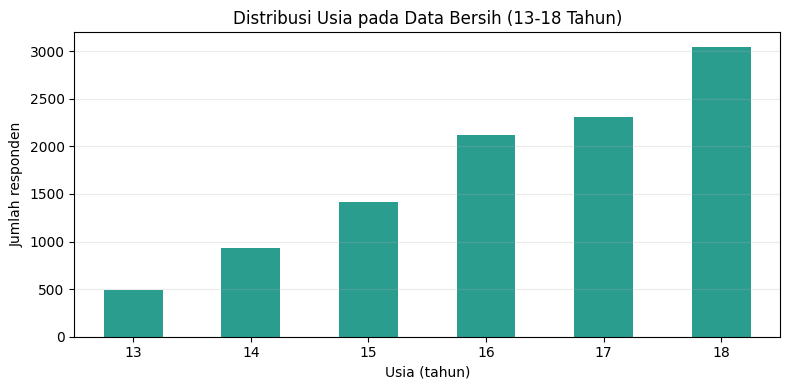

In [3]:
# Distribusi usia responden pada data bersih (13-18 tahun)
from pathlib import Path
import pandas as pd

cleaned_data_relative_path = Path('Data') / 'processed' / 'cleaned_data.csv'
cleaned_data_candidates = [
    Path.cwd() / cleaned_data_relative_path,
    Path.cwd().parent / cleaned_data_relative_path,
]
cleaned_data_path = next((path for path in cleaned_data_candidates if path.is_file()), None)
if cleaned_data_path is None:
    raise FileNotFoundError(
        'Data/processed/cleaned_data.csv tidak ditemukan. Jalankan preprocessing sekali atau periksa lokasi file data bersih.'
    )

df_clean = pd.read_csv(cleaned_data_path)
age_values = pd.to_numeric(df_clean['age'], errors='coerce')
age_counts = (
    age_values[age_values.between(13, 18)]
    .value_counts()
    .reindex(range(13, 19), fill_value=0)
    .sort_index()
)
total_age_group = int(age_counts.sum())
age_distribution = pd.DataFrame({'Jumlah responden': age_counts.astype(int)})
age_distribution['Persentase dalam kelompok usia 13-18 (%)'] = (
    age_counts.div(total_age_group).mul(100).round(2)
    if total_age_group else 0.0
)
age_distribution.index.name = 'Usia (tahun)'

print(f'Jumlah baris pada data bersih: {len(df_clean):,}')
print(f'Jumlah responden usia 13-18 tahun: {total_age_group:,}')
display(age_distribution)

import matplotlib.pyplot as plt
ax = age_counts.plot(kind='bar', figsize=(8, 4), color='#2a9d8f')
ax.set_title('Distribusi Usia pada Data Bersih (13-18 Tahun)')
ax.set_xlabel('Usia (tahun)')
ax.set_ylabel('Jumlah responden')
ax.set_xticklabels([str(age) for age in age_counts.index], rotation=0)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()